# CA1 – Statistical Analysis of Credit Card Default Data

**Module:** Stats for Data Analytics  
**Programme:** Higher Diploma in Data Analytics in Business  
**Student ID:** 2026328  
**Assignment:** CA1  
**GitHub Repository:** https://github.com/2026328-Dashzeveg-Purevtogtokh/Statistical-Techniques-Sep26

This notebook analyses the **Default of Credit Card Clients** dataset using Python.  
The analysis includes descriptive statistics, visualisations, and three probability distributions: **Binomial, Poisson, and Normal**.

## 1. Import Libraries

In [37]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import binom, poisson, norm

## 2. Load and Prepare the Dataset

In [ ]:
rawData = pd.read_excel("data/default of credit card clients.xls", header=1)
df = rawData.copy()
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '..data/default of credit card clients.xls'

In [4]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6', 'default']


In [3]:
# Rename target value
df.columns = [col.strip().lower().replace(" ", "_") for col in df.columns]
df = df.rename(columns={"default_payment_next_month": "default"})

In [5]:
df = df.map(lambda s: s.lower() if isinstance(s, str) else s)

## 3. Dataset Overview and Data Quality Check

Before the statistical analysis, the dataset is checked for size, missing values, duplicate rows, and data types.

In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (30000, 25)


In [7]:
print("\nMissing values:", int(df.isnull().sum().sum()))


Missing values: 0


In [8]:
print("Duplicate rows:", int(df.duplicated().sum()))

Duplicate rows: 0


In [9]:
print("\nData types:")
df.dtypes


Data types:


id           int64
limit_bal    int64
sex          int64
education    int64
marriage     int64
age          int64
pay_0        int64
pay_2        int64
pay_3        int64
pay_4        int64
pay_5        int64
pay_6        int64
bill_amt1    int64
bill_amt2    int64
bill_amt3    int64
bill_amt4    int64
bill_amt5    int64
bill_amt6    int64
pay_amt1     int64
pay_amt2     int64
pay_amt3     int64
pay_amt4     int64
pay_amt5     int64
pay_amt6     int64
default      int64
dtype: object

In [12]:
df[["sex", "education", "marriage", "default"]].nunique().to_frame(
    "Number of categories"
)

,Number of categories
sex,2
education,7
marriage,4
default,2


**Interpretation:**  
The dataset contains **30,000 customer records and 25 columns**. There are no missing values and no exact duplicate rows. Therefore, major data cleaning is not required. The target variable `default` contains two values, `0` and `1`, which makes it suitable for later Binomial analysis.

## 4. Variable Classification

Different types of variables require different statistical methods.

- `sex`, `education`, and `marriage` are categorical variables.
- `default` is a binary discrete target variable.
- Credit limit, age, bill amounts, and payment amounts are numerical variables.
- `pay_0` to `pay_6` are coded repayment-status variables. They are not treated as normal continuous measurements.

In [16]:
# Check how pandas currently stores each column
df.dtypes

id              int64
limit_bal       int64
sex          category
education    category
marriage     category
age             int64
pay_0           int64
pay_2           int64
pay_3           int64
pay_4           int64
pay_5           int64
pay_6           int64
bill_amt1       int64
bill_amt2       int64
bill_amt3       int64
bill_amt4       int64
bill_amt5       int64
bill_amt6       int64
pay_amt1        int64
pay_amt2        int64
pay_amt3        int64
pay_amt4        int64
pay_amt5        int64
pay_amt6        int64
default         int64
dtype: object

In [13]:
categorical_cols = ["sex", "education", "marriage"]

numerical_cols = [
    "limit_bal",
    "age",
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6",
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6",
]

repayment_status_cols = ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]

variable_groups = pd.DataFrame(
    {
        "Group": [
            "Categorical",
            "Binary target",
            "Continuous / numerical",
            "Repayment status (coded)",
        ],
        "Examples": [
            ", ".join(categorical_cols),
            "default",
            "limit_bal, age, bill_amt1, pay_amt1, ...",
            ", ".join(repayment_status_cols),
        ],
    }
)

variable_groups

,Group,Examples
0,Categorical,"sex, education, marriage"
1,Binary target,default
2,Continuous / numerical,"limit_bal, age, bill_amt1, pay_amt1, ..."
3,Repayment status (coded),"pay_0, pay_2, pay_3, pay_4, pay_5, pay_6"


In [14]:
# Convert categorical variables
df[categorical_cols] = df[categorical_cols].astype("category")

# Convert numerical variables
df[numerical_cols] = df[numerical_cols].apply(pd.to_numeric, errors="raise")

# Keep repayment-status codes as integers
df[repayment_status_cols] = (
    df[repayment_status_cols].apply(pd.to_numeric, errors="raise").astype("int64")
)

# Keep the binary target as integers: 0 = No default, 1 = Default
df["default"] = pd.to_numeric(df["default"], errors="raise").astype("int64")

# Check the updated data types
df[categorical_cols + numerical_cols + repayment_status_cols + ["default"]].dtypes

sex          category
education    category
marriage     category
limit_bal       int64
age             int64
bill_amt1       int64
bill_amt2       int64
bill_amt3       int64
bill_amt4       int64
bill_amt5       int64
bill_amt6       int64
pay_amt1        int64
pay_amt2        int64
pay_amt3        int64
pay_amt4        int64
pay_amt5        int64
pay_amt6        int64
pay_0           int64
pay_2           int64
pay_3           int64
pay_4           int64
pay_5           int64
pay_6           int64
default         int64
dtype: object

## 5. Descriptive Statistics

Descriptive statistics are used to summarise the **centre, spread, range, and shape** of selected numerical variables.

The main measures used are:
- **Mean** and **median** for the centre,
- **standard deviation** for spread,
- **minimum and maximum** for range,
- **skewness** for distribution shape.

In [17]:
selected_numeric = ["limit_bal", "age", "bill_amt1", "pay_amt1"]

df[selected_numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
limit_bal,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.0,1000000.0
age,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.0,79.0
bill_amt1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.0,964511.0
pay_amt1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.0,873552.0


In [18]:
summary_stats = pd.DataFrame(
    {
        "Mean": df[selected_numeric].mean(),
        "Median": df[selected_numeric].median(),
        "Standard Deviation": df[selected_numeric].std(),
        "Minimum": df[selected_numeric].min(),
        "Maximum": df[selected_numeric].max(),
        "Skewness": df[selected_numeric].skew(),
    }
)

summary_stats.round(2)

,Mean,Median,Standard Deviation,Minimum,Maximum,Skewness
limit_bal,167484.32,140000.0,129747.66,10000,1000000,0.99
age,35.49,34.0,9.22,21,79,0.73
bill_amt1,51223.33,22381.5,73635.86,-165580,964511,2.66
pay_amt1,5663.58,2100.0,16563.28,0,873552,14.67


In [19]:
default_summary = pd.DataFrame(
    {
        "Count": df["default"].value_counts().sort_index(),
        "Percentage": (
            df["default"].value_counts(normalize=True).sort_index() * 100
        ).round(2),
    }
)

default_summary

,Count,Percentage
default,,
0,23364,77.88
1,6636,22.12


**Interpretation:**  
The average credit limit is about **167,484**, while the median is **140,000**, and the skewness is about **0.99**. This shows a positive skew. Customer age has a mean of about **35.49 years**, a median of **34 years**, and skewness of about **0.73**, so it is also positively skewed but less strongly.

`bill_amt1` is more strongly skewed, while `pay_amt1` has very high positive skewness. This means that a small number of very large financial values increase the mean. The default rate is **22.12%**, while **77.88%** of customers did not default.

## 6. Data Visualisation

The following graphs support the descriptive statistics. They show the balance of the target variable and the shapes of two important numerical variables.

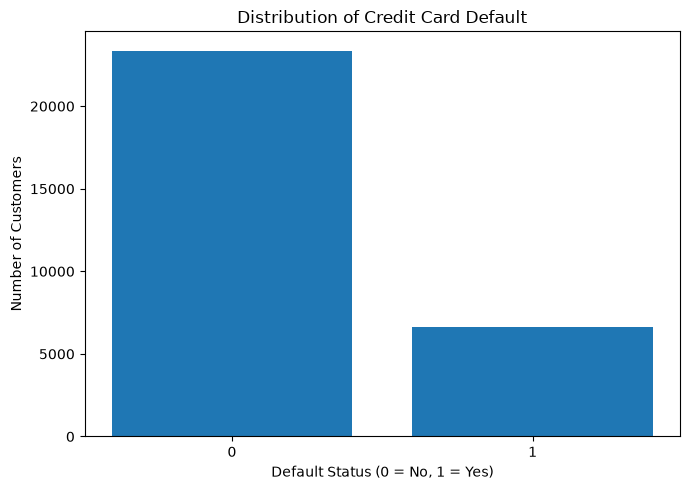

In [20]:
plt.figure(figsize=(7, 5))

counts = df["default"].value_counts().sort_index()
plt.bar(counts.index.astype(str), counts.values)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

The default graph shows that most customers did not default. About **22.12%** defaulted and **77.88%** did not. Because this variable has only two possible outcomes, it is suitable for Binomial analysis.

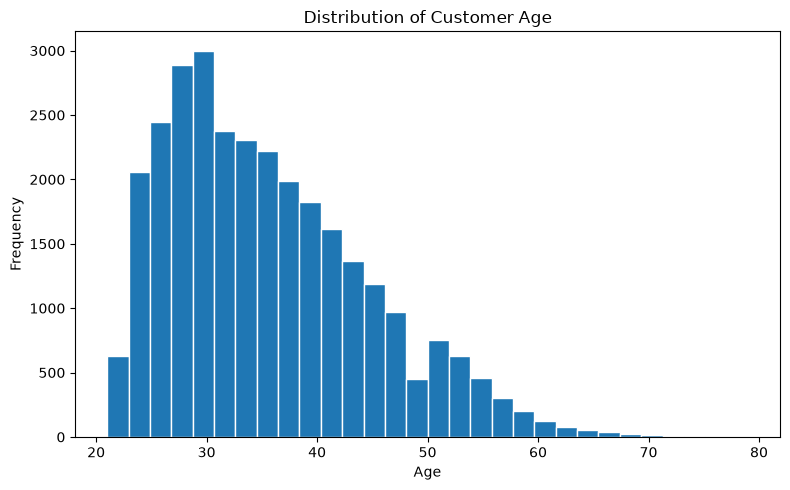

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=30, edgecolor="white")

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

The age distribution is concentrated mainly around the late twenties, thirties, and early forties. The longer right tail supports the positive skewness value of about **0.73**.

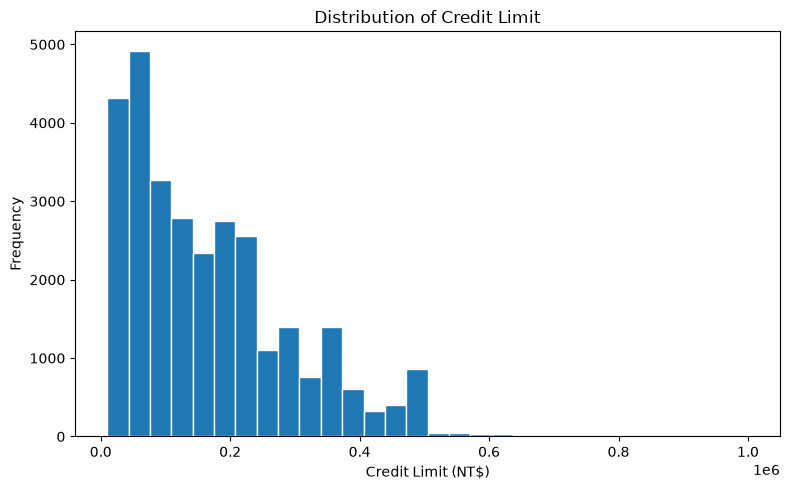

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(df["limit_bal"], bins=30, edgecolor="white")

plt.title("Distribution of Credit Limit")
plt.xlabel("Credit Limit (NT$)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

The credit-limit distribution is positively skewed. Most customers have low to medium credit limits, while a smaller group has very high limits. This is consistent with the mean being higher than the median.

## 7. Binomial Distribution

The `default` variable is suitable for a Binomial distribution because each customer has two possible outcomes:

- `1` = default
- `0` = no default

For a Binomial random variable:

\[
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}
\]

where:
- \(n\) is the number of customers,
- \(k\) is the number of defaults,
- \(p\) is the observed probability of default.

In [24]:
p_default = df["default"].mean()

n = 10
k = 3

probability_3_defaults = binom.pmf(k, n, p_default)
expected_10 = n * p_default
variance_10 = n * p_default * (1 - p_default)

print(f"Observed probability of default: {p_default:.4f} ({p_default * 100:.2f}%)")
print(f"Expected defaults among 10 customers: {expected_10:.3f}")
print(f"Variance for n=10: {variance_10:.3f}")
print(f"Probability of exactly 3 defaults: {probability_3_defaults:.4f}")

Observed probability of default: 0.2212 (22.12%)
Expected defaults among 10 customers: 2.212
Variance for n=10: 1.723
Probability of exactly 3 defaults: 0.2257


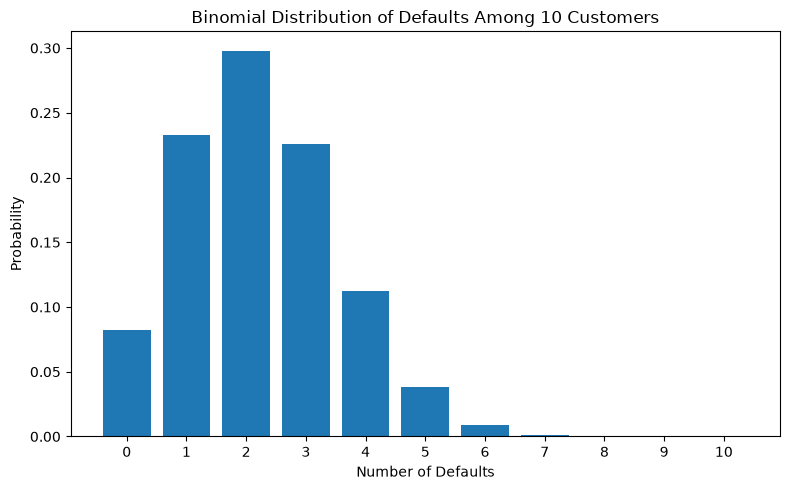

In [25]:
x = np.arange(0, n + 1)

plt.figure(figsize=(8, 5))
plt.bar(x, binom.pmf(x, n, p_default))

plt.title("Binomial Distribution of Defaults Among 10 Customers")
plt.xlabel("Number of Defaults")
plt.ylabel("Probability")
plt.xticks(x)
plt.tight_layout()
plt.show()

For 10 customers, the expected number of defaults is about **2.21**. The highest probabilities are around two or three defaults, which is consistent with the observed default probability.

Expected defaults for n=100: 22.12
np = 22.12
n(1-p) = 77.88


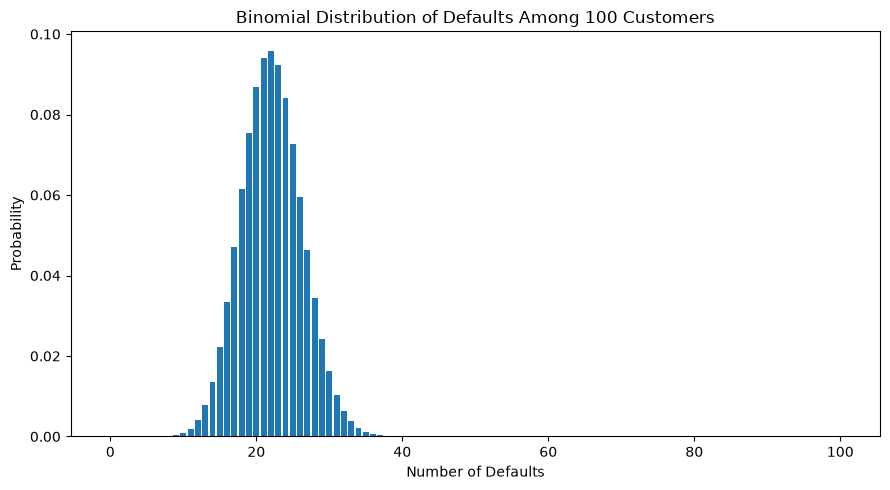

In [26]:
n_large = 100
x_large = np.arange(0, n_large + 1)
prob_large = binom.pmf(x_large, n_large, p_default)

expected_100 = n_large * p_default
non_default_expected = n_large * (1 - p_default)

print(f"Expected defaults for n=100: {expected_100:.2f}")
print(f"np = {expected_100:.2f}")
print(f"n(1-p) = {non_default_expected:.2f}")

plt.figure(figsize=(9, 5))
plt.bar(x_large, prob_large)

plt.title("Binomial Distribution of Defaults Among 100 Customers")
plt.xlabel("Number of Defaults")
plt.ylabel("Probability")
plt.tight_layout()
plt.show()

When the sample size increases to **100**, the distribution becomes smoother and more bell-shaped around the expected value of **22.12 defaults**.

For \(n=100\), both \(np=22.12\) and \(n(1-p)=77.88\) are well above 5. This helps explain why the Binomial distribution is closer to a Normal shape for the larger sample. For \(n=10\), \(np=2.21\), so the Normal approximation is less suitable.

## 8. Poisson Distribution

The Poisson distribution is used for count data. To explore it in this dataset, a new variable called `late_payment_count` is created by counting the months where the repayment-status code is greater than zero.

The Poisson probability is:

\[
P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!}
\]

where \(\lambda\) is the average number of events.

A Poisson model assumes that events occur independently and at a stable average rate. These assumptions are checked against the observed data.

In [27]:
df["late_payment_count"] = (df[repayment_status_cols] > 0).sum(axis=1)

late_payment_frequency = (
    df["late_payment_count"].value_counts().sort_index().to_frame("Customers")
)

late_payment_frequency

,Customers
late_payment_count,
0,19931
1,4426
2,1899
3,1154
4,951
5,298
6,1341


In [28]:
lambda_late = df["late_payment_count"].mean()
variance_late = df["late_payment_count"].var()
prob_2_late = poisson.pmf(2, mu=lambda_late)

print(f"Mean late-payment count (lambda): {lambda_late:.4f}")
print(f"Variance of late-payment count: {variance_late:.4f}")
print(f"Variance / mean ratio: {variance_late / lambda_late:.2f}")
print(f"Poisson probability of exactly 2 late-payment months: {prob_2_late:.4f}")

Mean late-payment count (lambda): 0.8342
Variance of late-payment count: 2.4159
Variance / mean ratio: 2.90
Poisson probability of exactly 2 late-payment months: 0.1511


In [29]:
x = np.arange(0, 7)

observed = (
    df["late_payment_count"]
    .value_counts(normalize=True)
    .sort_index()
    .reindex(x, fill_value=0)
)

poisson_probs = poisson.pmf(x, mu=lambda_late)

comparison = pd.DataFrame(
    {"Late Payments": x, "Observed": observed.values, "Poisson": poisson_probs}
)

comparison.round(4)

,Late Payments,Observed,Poisson
0,0,0.6644,0.4342
1,1,0.1475,0.3622
2,2,0.0633,0.1511
3,3,0.0385,0.0420
4,4,0.0317,0.0088
5,5,0.0099,0.0015
6,6,0.0447,0.0002


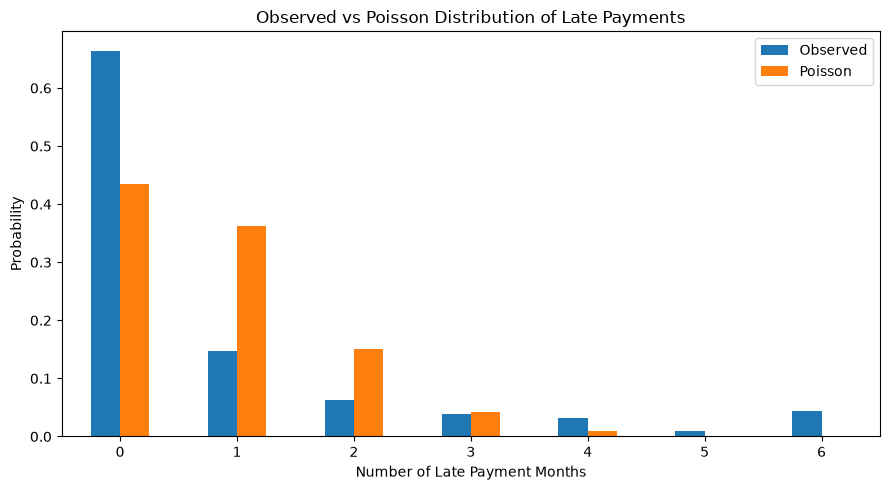

In [30]:
comparison.plot(
    x="Late Payments", y=["Observed", "Poisson"], kind="bar", figsize=(9, 5)
)

plt.title("Observed vs Poisson Distribution of Late Payments")
plt.xlabel("Number of Late Payment Months")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:**  
The observed late-payment distribution does not closely match the fitted Poisson distribution. There are more customers with **zero** late-payment months and **six** late-payment months than the model predicts.

The mean late-payment count is about **0.83**, while the variance is much larger, at about **2.42**. A simple Poisson model usually expects the mean and variance to be similar, so this difference is another sign that the model is not a close fit.

In addition, the count is limited to six months, and late-payment behaviour across months may not be independent. Therefore, the Poisson distribution is useful for exploring the count variable, but its limitations should be clearly recognised.

## 9. Normal Distribution

Customer `age` is selected for Normal distribution analysis because it is a continuous numerical variable and is less skewed than the selected financial variables.

A Normal distribution is described mainly by its mean \(\mu\) and standard deviation \(\sigma\). A perfectly Normal distribution is symmetric, so its skewness is close to zero.

In [31]:
age_mean = df["age"].mean()
age_std = df["age"].std()
age_skew = df["age"].skew()

print(f"Mean age: {age_mean:.2f}")
print(f"Standard deviation: {age_std:.2f}")
print(f"Skewness: {age_skew:.2f}")

Mean age: 35.49
Standard deviation: 9.22
Skewness: 0.73


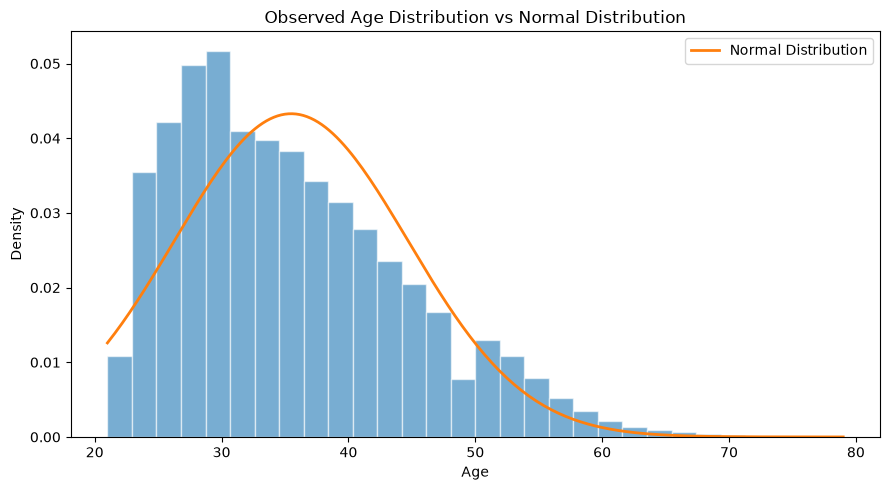

In [32]:
plt.figure(figsize=(9, 5))

plt.hist(df["age"], bins=30, density=True, alpha=0.6, edgecolor="white")

x = np.linspace(df["age"].min(), df["age"].max(), 200)
normal_curve = norm.pdf(x, loc=age_mean, scale=age_std)

plt.plot(x, normal_curve, linewidth=2, label="Normal Distribution")

plt.title("Observed Age Distribution vs Normal Distribution")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

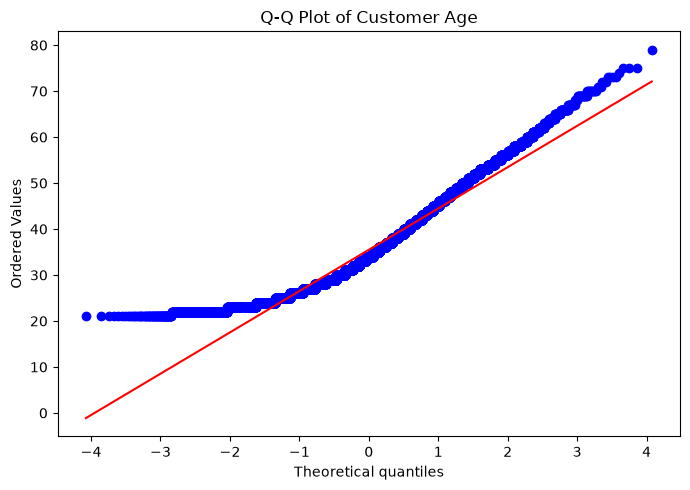

In [33]:
plt.figure(figsize=(7, 5))

stats.probplot(df["age"], dist="norm", plot=plt)

plt.title("Q-Q Plot of Customer Age")
plt.tight_layout()
plt.show()

The histogram and Q-Q plot show that age is **not perfectly Normal**. The middle part of the distribution is reasonably close to the Normal pattern, but the tails differ from the reference line. The positive skewness of about **0.73** also shows that the distribution has a longer right tail.

In [34]:
prob_age_30_40 = norm.cdf(40, loc=age_mean, scale=age_std) - norm.cdf(
    30, loc=age_mean, scale=age_std
)

actual_age_30_40 = df["age"].between(30, 40).mean()

difference_pp = abs(prob_age_30_40 - actual_age_30_40) * 100

print(
    f"Normal model probability, age 30-40: {prob_age_30_40:.4f} ({prob_age_30_40 * 100:.2f}%)"
)
print(
    f"Observed proportion, age 30-40: {actual_age_30_40:.4f} ({actual_age_30_40 * 100:.2f}%)"
)
print(f"Absolute difference: {difference_pp:.2f} percentage points")

Normal model probability, age 30-40: 0.4120 (41.20%)
Observed proportion, age 30-40: 0.4036 (40.36%)
Absolute difference: 0.84 percentage points


The fitted Normal model estimates that about **41.20%** of customers are aged between 30 and 40, while the observed proportion is about **40.36%**. The difference is only about **0.84 percentage points**.

This shows that the Normal model gives a reasonable approximation for this central age range, even though the full age distribution is not perfectly Normal.

## 10. Comparison of Probability Distributions

The three distributions are compared below to show why each variable was selected and how well each model represents the data.

In [35]:
distribution_summary = pd.DataFrame(
    {
        "Distribution": ["Binomial", "Poisson", "Normal"],
        "Variable": ["default", "late_payment_count", "age"],
        "Variable Type": ["Binary discrete", "Count discrete", "Continuous"],
        "Main Parameter": [
            f"p = {p_default:.4f}",
            f"lambda = {lambda_late:.4f}",
            f"mean = {age_mean:.2f}, std = {age_std:.2f}",
        ],
        "Main Finding": [
            "Good conceptual fit",
            "Weak observed fit",
            "Reasonable central approximation",
        ],
    }
)

distribution_summary

,Distribution,Variable,Variable Type,Main Parameter,Main Finding
0,Binomial,default,Binary discrete,p = 0.2212,Good conceptual fit
1,Poisson,late_payment_count,Count discrete,lambda = 0.8342,Weak observed fit
2,Normal,age,Continuous,"mean = 35.49, std = 9.22",Reasonable central approximation


The **Binomial distribution** is suitable for `default` because the variable has two outcomes. The **Poisson distribution** can be explored with `late_payment_count` because it is count data, but the observed distribution does not closely follow the fitted Poisson model. The **Normal distribution** is applied to `age` because it is continuous and less skewed than the selected financial variables.

The discrete variables should not be directly treated as Normal variables in this analysis. `default` only contains `0` and `1`, while `late_payment_count` contains integer values from `0` to `6`. However, the **number of defaults in a large Binomial sample** can become approximately Normal when the sample size is sufficiently large.

Overall, the analysis shows that the choice of probability distribution should depend on the **type, shape, and behaviour** of the variable.

## 11. Conclusion

The dataset contains both categorical and numerical variables and is suitable for different statistical techniques. Descriptive statistics showed positive skewness in several financial variables, while age was closer to a Normal shape.

The Binomial distribution was a good choice for the binary default variable. The larger sample example showed how its shape becomes smoother and closer to Normal. The Poisson distribution was useful for exploring late-payment counts, but it did not fit the observed data closely. The Normal distribution gave a reasonable approximation for the central part of the age data, although the full distribution remained positively skewed.

Overall, the results show why statistical distributions should be selected according to the characteristics of the data rather than applying the same model to every variable.

## 12. Reference

Yeh, I.-C. (2009) *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. doi:10.24432/C55S3H.